# M4 results: text–face agreement (Gate 3)

## Results summary

Each claim points to the section that supports it; each section opens with what its plot shows.

* The text-derived valence direction reads faces with no training. Emotion vectors extracted purely from text (gemotions, reproduced in Gate 0) were projected onto Gemma 4’s activations for face images. On held-out actors across two acted datasets, that zero-training readout separates positive from negative expression with AUC 0.98, and four-way among negative emotions at 58 percent against 25 chance and 66 for human raters. That matches a dedicated facial-expression model and a blendshape regression trained for the task. This is the strongest evidence that at least the valence axis is shared across modalities. *(Section 9, Gate 1 row.)*

* The readout survives real video and natural reading. In acted video, the sentence being spoken explains under 1 percent of the readout’s variance against 73 for the emotion, speech motion sits ten SDs below the expression gap after windowing, and expression onsets coincide with geometric landmark onsets. In the recorded reading takes, the mean readout per take separates positive from negative stories with AUC 0.90, with nothing fitted to the reader beyond a per-session offset. *(Section 9, Gate 2 row; section 2.)*

* The organization of the face space mirrors the text taxonomy. Clustering frame-level emotion profiles from 21 takes gives clusters that march through the paper’s ten clusters in valence order, from Fear and Overwhelm through Hostile Anger to Exuberant Joy, with positive and negative stories at opposite ends of the embedding. *(Section 7.)*

* Shared directions, but not the same origin. The reading face carries a constant profile, reflective and nostalgic, that dominates absolute scores, and the calibration face sits outside the reading manifold entirely. The text and face activations live in different regions of the space; what transfers is the axes, not the coordinates. Any claim of “the same representation” has to be stated at that level. *(Section 7: the calibration island, the tags before and after standardizing.)*

* Beyond valence the evidence is weak. Category discrimination is above chance but modest, and the full 171-score profile agrees with the text only faintly: a cosine of 0.18 under a lightly trained map, indistinguishable from what blendshapes achieve. Whether finer emotion distinctions are shared, or only the valence axis plus arousal-like structure, is open. *(Section 1, the ridge and blendshape rows; section 9, the 4-way numbers.)*

* The sentence-level test did not pass, and the text side is why. Gate 3’s held-out correlation between face and text valence per sentence is -0.01. The text EVs are 85 to 90 percent within-story variation at sentence scale and rank neutral stories at the positive extreme, so the shared-axis hypothesis is currently untestable at fine time scales until the text target is fixed. *(Sections 1, 3, 4 and 6.)*

* Caveats on all of it: one subject for the reading data, performed expressions in the acted datasets, 18 story takes, and a numerically sensitive model whose deep-layer activations shift with hardware and precision, so every number is tied to one pinned configuration. *(Section 8 for the exact numbers; the work plan for the configuration.)*

## How this notebook is built

Plots of `results/m4/` as written by `scripts/m4_agreement.py` (reading condition only): the gate metrics against their nulls, the per-take face readout against the story labels, story-level versus within-story agreement, the lag search, example traces, and the clustering of frame-level emotion profiles. Regenerate the inputs with `.venv/bin/python scripts/m4_agreement.py --lag-grid=-1:2:0.25`, then run all cells; the cells come from `notebooks/make_m4_results.py`. Figures are saved to `results/m4/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq

ROOT = Path.cwd() if (Path.cwd() / "results" / "m4").exists() else Path.cwd().parent
M4 = ROOT / "results" / "m4"
FIG = M4 / "figures"
FIG.mkdir(parents=True, exist_ok=True)

metrics = json.loads((M4 / "agreement_metrics.json").read_text())
split = json.loads((M4 / "split.json").read_text())
seg_table = pq.read_table(M4 / "segments.parquet")
seg = {c: seg_table[c].to_numpy(zero_copy_only=False) for c in seg_table.column_names}
stories = {r["id"]: r for r in map(json.loads, (ROOT / "data/stories/stories.jsonl").read_text().splitlines()) if r}
COND = "read"

# Palette (the dataviz reference instance): categorical slots in fixed order; a cool/warm pair for polarity.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "magenta": "#e87ba4",
     "green": "#008300", "violet": "#6250d6", "red": "#e34948", "gray": "#9a9a96", "ink": "#0b0b0b", "ink2": "#52514e"}
POS_COL, NEG_COL, NEU_COL = C["blue"], C["orange"], C["gray"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10, "legend.frameon": False})

POS = {"Exuberant Joy", "Compassionate Gratitude", "Peaceful Contentment", "Playful Amusement", "Competitive Pride"}
NEG = {"Despair and Shame", "Hostile Anger", "Fear and Overwhelm", "Depleted Disengagement", "Vigilant Suspicion"}

def polarity(story_id):
    """+1 / -1 for single-emotion stories by cluster, 0 for neutral, None for mixed (turn) stories."""
    st = stories[story_id]
    if st.get("kind") == "neutral":
        return 0
    cl = st.get("clusters", [])
    if st.get("kind") != "single" or len(cl) != 1:
        return None
    return 1 if cl[0] in POS else -1 if cl[0] in NEG else None

def pol_color(p):
    return POS_COL if p == 1 else NEG_COL if p == -1 else NEU_COL

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

read = seg["condition"] == COND
held = seg["split"] == "heldout" if "split" in seg else np.isin(seg["story"], split["holdout_stories"]) | (seg["session"] == split["holdout_session"])
ok = np.isfinite(seg["face_valence_z"]) & np.isfinite(seg["text_valence_z"])
H = metrics["results"]["heldout"][COND]
print(metrics["dataset"]["n_segments"], "segments;", metrics["dataset"]["heldout_segments"], "held-out;",
      "held-out session", split["holdout_session"], "+", len(split["holdout_stories"]), "held-out stories;",
      "lag", metrics["lag"]["lag"], "s")

170 segments; 123 held-out; held-out session 20261109-2316 + 15 held-out stories; lag -0.25 s


## 1. Gate 3 at a glance

**What it shows.** The zero-training readout's sentence-level valence correlation sits inside its null band, so Gate 3 is not passed. Only profile-level agreement under a fitted map clears the null (cosine 0.18), and the blendshape baseline does as well, which is why the evidence beyond valence is called weak in the summary.

How to read it: each held-out metric is a dot against its story-level permutation null (grey band, mean ± 2 SD of 1000 permutations). A blue dot to the right of its band clears p < 0.05; a grey dot inside it is noise. Rows: the zero-training readout, the ridge map fitted on development segments, and the blendshape baseline (same ridge recipe on MediaPipe blendshapes).

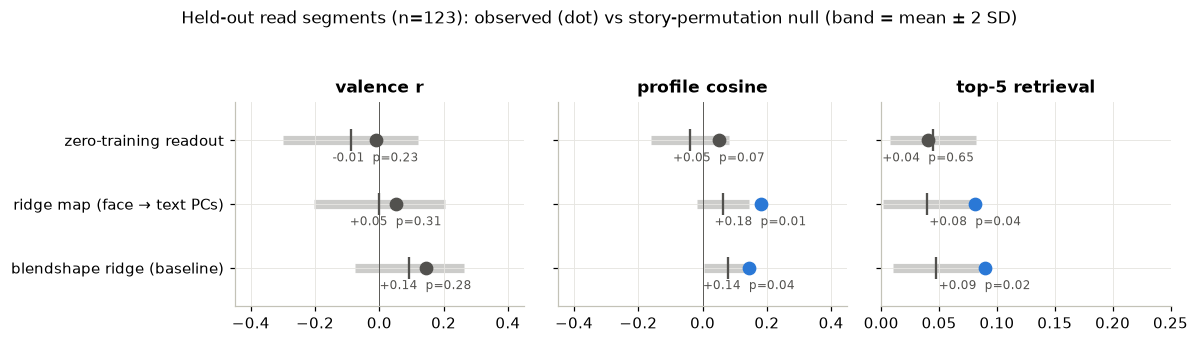

Gate 3 valence: no (r -0.01, p 0.23); turns: no


In [2]:
variants = [("zero_training", "zero-training readout"), ("ridge", "ridge map (face → text PCs)"), ("blendshapes", "blendshape ridge (baseline)")]
stats = [("valence_r", "valence r"), ("cosine", "profile cosine"), ("top5", "top-5 retrieval")]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
for ax, (key, label) in zip(axes, stats):
    for i, (vk, vlabel) in enumerate(variants):
        R = H.get(vk)
        if not R or "p" not in R:
            continue
        obs = R["retrieval"]["top5"] if key == "top5" else R[key]
        mu, sd = R["null_mean"][f"{key}_story"], R["null_sd"][f"{key}_story"]
        p = R["p"][f"{key}_story"]
        ax.plot([mu - 2 * sd, mu + 2 * sd], [i, i], color=C["gray"], lw=6, solid_capstyle="butt", alpha=0.5, zorder=1)
        ax.plot(mu, i, "|", color=C["ink2"], ms=14, mew=1.5, zorder=2)
        ax.plot(obs, i, "o", color=C["blue"] if p < 0.05 else C["ink2"], ms=8, zorder=3)
        ax.annotate(f"{obs:+.2f}  p={p:.2f}", (obs, i), xytext=(0, -14), textcoords="offset points",
                    ha="center", fontsize=8, color=C["ink2"])
    ax.set_yticks(range(len(variants))); ax.set_yticklabels([v[1] for v in variants]); ax.invert_yaxis()
    ax.set_ylim(len(variants) - 0.4, -0.6)
    ax.set_title(label); ax.axvline(0, color=C["ink2"], lw=0.6)
axes[0].set_xlim(-0.45, 0.45); axes[1].set_xlim(-0.45, 0.45); axes[2].set_xlim(0, 0.25)
fig.suptitle(f"Held-out {COND} segments (n={H['zero_training']['n_segments']}): observed (dot) vs story-permutation null (band = mean ± 2 SD)",
             y=1.06, fontsize=11)
fig.tight_layout()
save(fig, "01_gate_vs_null"); plt.show()
g = metrics["gate3"]
print("Gate 3 valence:", "pass" if g["valence"]["pass"] else "no", f"(r {g['valence']['r']:+.2f}, p {g['valence']['p_story']:.2f});",
      "turns:", "pass" if g["turn"]["pass"] else "no")

## 2. The face readout per take, against the story label

**What it shows.** Averaged over a take, the face readout tracks the emotion of the story being read: positive stories to the right, negative to the left, AUC 0.90 over the single-emotion takes, with nothing fitted to the reader beyond a per-session offset. The text side (diamonds) lines up less cleanly, with the neutral story at the far right.

How to read it: one bar per reading take, its mean face valence z-scored on development data, sorted. Bars are colored by the story's labelled polarity, not by the model, so a correct readout shows as blue bars right and orange bars left. The diamond is the text's story mean on the same z scale.

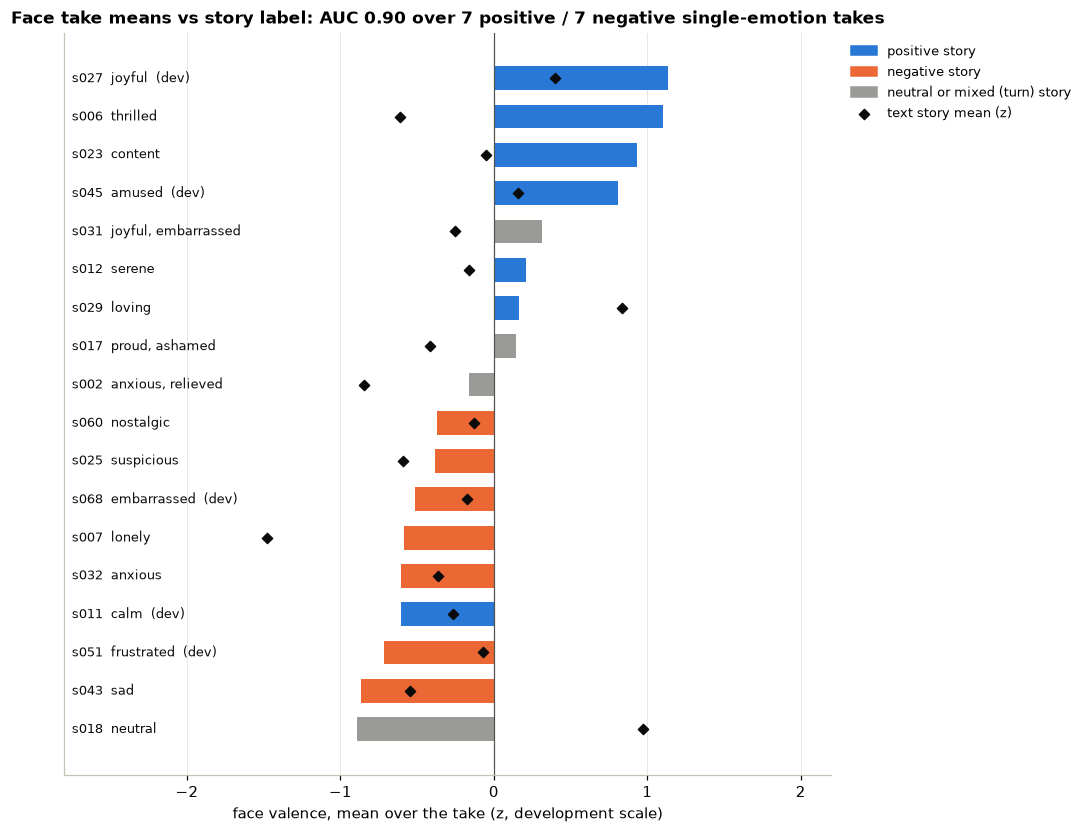

In [3]:
rows = []
for (sess, take, story) in sorted({(s, t, st) for s, t, st in zip(seg["session"], seg["take"], seg["story"]) if True}):
    m = read & ok & (seg["take"] == take) & (seg["session"] == sess)
    if not m.any():
        continue
    rows.append({"session": sess, "take": take, "story": story, "face": seg["face_valence_z"][m].mean(),
                 "text": seg["text_valence_z"][m].mean(), "pol": polarity(story), "held": bool(held[m].all()),
                 "label": ", ".join(stories[story].get("emotions") or ["neutral"]), "kind": stories[story].get("kind")})
rows.sort(key=lambda r: r["face"])
fig, ax = plt.subplots(figsize=(9, 0.42 * len(rows) + 1.2))
y = np.arange(len(rows))
ax.barh(y, [r["face"] for r in rows], color=[pol_color(r["pol"]) for r in rows], height=0.62, zorder=2)
ax.scatter([r["text"] for r in rows], y, marker="D", s=22, color=C["ink"], zorder=3, label="text story mean (z)")
for yi, r in zip(y, rows):
    ax.text(-2.75, yi, f"{r['story']}  {r['label']}" + ("" if r["held"] else "  (dev)"), va="center", ha="left", fontsize=8.5, color=C["ink"])
ax.set_yticks([]); ax.set_xlim(-2.8, 2.2); ax.axvline(0, color=C["ink2"], lw=0.8)
ax.set_xlabel("face valence, mean over the take (z, development scale)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=POS_COL, label="positive story"), Patch(color=NEG_COL, label="negative story"),
                   Patch(color=NEU_COL, label="neutral or mixed (turn) story"), ax.collections[0]],
          loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8.5)
single = [r for r in rows if r["pol"] in (1, -1)]
from cogmirror import metrics as M
auc = M.auc(np.array([r["face"] for r in single if r["pol"] == 1]), np.array([r["face"] for r in single if r["pol"] == -1]))
ax.set_title(f"Face take means vs story label: AUC {auc:.2f} over {sum(r['pol']==1 for r in single)} positive / {sum(r['pol']==-1 for r in single)} negative single-emotion takes")
save(fig, "02_take_means_vs_label"); plt.show()

## 3. Story level versus within story

**What it shows.** Agreement exists between stories (left, r +0.32 once the neutral story is set aside) and not within them (right, r near zero). The readout tracks which story is being read, not which sentence, which is the level at which Gate 3 is scored.

How to read it: left, one point per take, text story mean against face take mean, colored by label polarity. Right, the same segments after subtracting each story's mean from both sides, i.e. the sentence-to-sentence agreement Gate 3 scores.

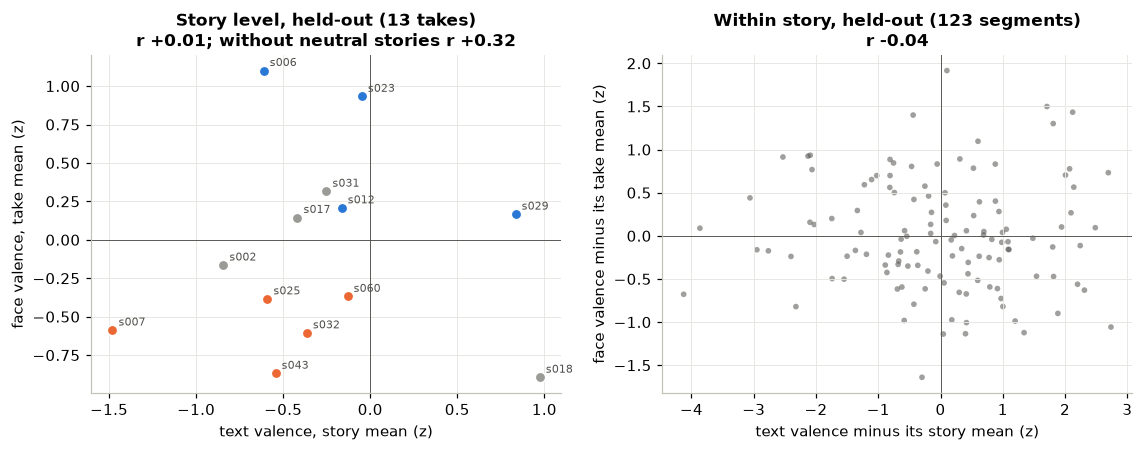

In [4]:
def story_and_within(mask):
    m = mask & ok
    f, x, key = seg["face_valence_z"][m], seg["text_valence_z"][m], np.char.add(seg["session"][m], seg["take"][m])
    units = np.unique(key)
    fm = {u: f[key == u].mean() for u in units}; xm = {u: x[key == u].mean() for u in units}
    fw = f - np.array([fm[u] for u in key]); xw = x - np.array([xm[u] for u in key])
    return (np.array([fm[u] for u in units]), np.array([xm[u] for u in units]), units), (fw, xw, key)

(F, X, units), (fw, xw, key) = story_and_within(read & held)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]
for u, f, x in zip(units, F, X):
    story = seg["story"][np.char.add(seg["session"], seg["take"]) == u][0]
    ax.scatter(x, f, s=46, color=pol_color(polarity(story)), edgecolor="white", lw=1, zorder=3)
    ax.annotate(story, (x, f), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=C["ink2"])
r_story = np.corrcoef(X, F)[0, 1]
nn = np.array([polarity(seg["story"][np.char.add(seg["session"], seg["take"]) == u][0]) != 0 for u in units])
r_nn = np.corrcoef(X[nn], F[nn])[0, 1]
ax.set_title(f"Story level, held-out ({len(F)} takes)\nr {r_story:+.2f}; without neutral stories r {r_nn:+.2f}")
ax.set_xlabel("text valence, story mean (z)"); ax.set_ylabel("face valence, take mean (z)")
ax.axhline(0, color=C["ink2"], lw=0.6); ax.axvline(0, color=C["ink2"], lw=0.6)
ax = axes[1]
ax.scatter(xw, fw, s=14, color=C["ink2"], alpha=0.55, edgecolor="none")
r_within = np.corrcoef(xw, fw)[0, 1]
ax.set_title(f"Within story, held-out ({len(fw)} segments)\nr {r_within:+.2f}")
ax.set_xlabel("text valence minus its story mean (z)"); ax.set_ylabel("face valence minus its take mean (z)")
ax.axhline(0, color=C["ink2"], lw=0.6); ax.axvline(0, color=C["ink2"], lw=0.6)
fig.tight_layout(); save(fig, "03_story_vs_within"); plt.show()

## 4. Where the variance is

**What it shows.** About half of the face signal is "which story"; only about a tenth of the text signal is. At sentence scale the text target is mostly within-story variation, so the sentence-level test fails on the text side before the face side is even tested.

How to read it: the bar is the share of each modality's valence variance that lies between stories (take means) rather than within them, for the held-out, development and pooled segments.

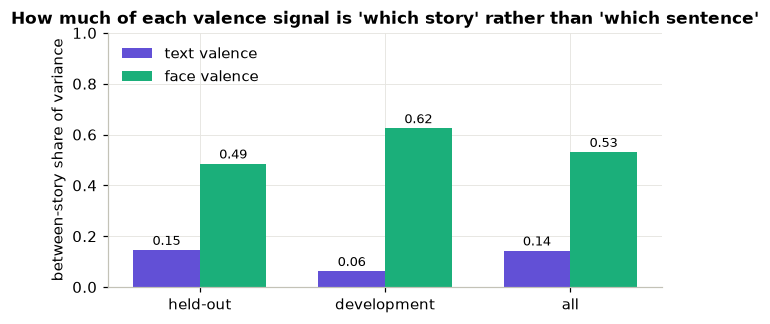

In [5]:
def between_share(mask, col):
    m = mask & ok
    v, key = seg[col][m], np.char.add(seg["session"][m], seg["take"][m])
    means = {u: v[key == u].mean() for u in np.unique(key)}
    return np.var(np.array([means[u] for u in key])) / np.var(v)

subsets = [("held-out", read & held), ("development", read & ~held), ("all", read)]
fig, ax = plt.subplots(figsize=(6.5, 3))
w = 0.36; xs = np.arange(len(subsets))
tb = [between_share(m, "text_valence_z") for _, m in subsets]; fb = [between_share(m, "face_valence_z") for _, m in subsets]
ax.bar(xs - w / 2, tb, w, color=C["violet"], label="text valence", zorder=2)
ax.bar(xs + w / 2, fb, w, color=C["aqua"], label="face valence", zorder=2)
for x, t, f in zip(xs, tb, fb):
    ax.text(x - w / 2, t + 0.02, f"{t:.2f}", ha="center", fontsize=8.5); ax.text(x + w / 2, f + 0.02, f"{f:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels([s for s, _ in subsets]); ax.set_ylim(0, 1); ax.set_ylabel("between-story share of variance")
ax.set_title("How much of each valence signal is 'which story' rather than 'which sentence'"); ax.legend(loc="upper left")
save(fig, "04_variance_shares"); plt.show()

## 5. Lag search

**What it shows.** The curve is flat to within a few hundredths over three seconds, so timing is not what limits the agreement, and the chosen lag is near zero.

How to read it: development-data valence correlation as a function of the face–text lag (positive: the face trails the text). A flat curve means the lag is not identifiable from this much data; the analysis uses the plateau's center.

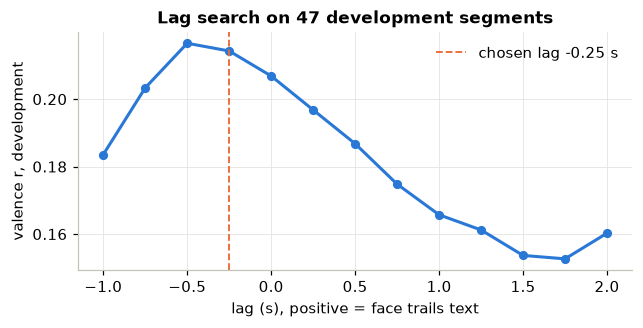

In [6]:
lag = metrics["lag"]
curve = lag["per_condition"].get(COND, lag)["curve"]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot([c["lag"] for c in curve], [c["r"] for c in curve], "-o", color=C["blue"], lw=2, ms=5)
ax.axvline(lag["lag"], color=C["orange"], lw=1.2, ls="--", label=f"chosen lag {lag['lag']:+.2f} s")
ax.set_xlabel("lag (s), positive = face trails text"); ax.set_ylabel("valence r, development"); ax.legend()
ax.set_title(f"Lag search on {curve[0]['n']} development segments")
save(fig, "05_lag_curve"); plt.show()

## 6. Example traces

**What it shows.** Even in the best-agreeing take the face moves on a one-to-three-second scale while the text steps once per sentence, and in the neutral story the text sits high where the face does not: the sentence-level target and the face signal have different time scales and, for neutral text, a different origin.

How to read it: face valence over time for held-out takes (the windowed series, standardized within the take) with the text's sentence valence as steps (also standardized within the take). Chosen: the takes with the best and the worst story-level agreement, plus a neutral story.

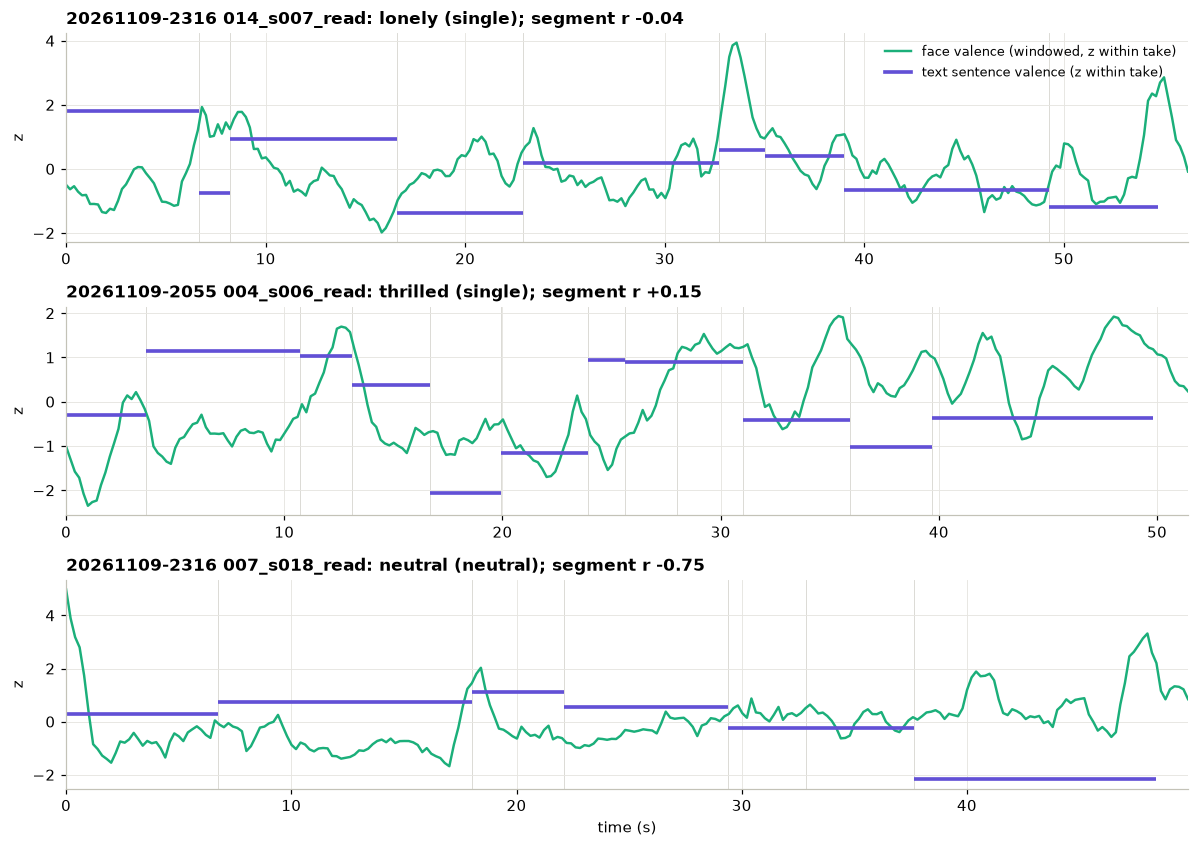

In [7]:
from cogmirror import align, store

def take_series(session, take):
    p = ROOT / "data" / "video" / session / take / f"{take}.parquet"
    cols, _ = store.read_parquet(p)
    return cols

def plot_take(ax, session, take, story):
    cols = take_series(session, take)
    t, v = cols["t"], cols["valence"]
    okv = np.isfinite(v)
    vz = (v - np.nanmean(v)) / (np.nanstd(v) + 1e-9)
    ax.plot(t[okv], vz[okv], color=C["aqua"], lw=1.6, label="face valence (windowed, z within take)")
    m = read & (seg["session"] == session) & (seg["take"] == take)
    tx = seg["text_valence_z"][m]; tz = (tx - tx.mean()) / (tx.std() + 1e-9)
    for s, e, z in zip(seg["start"][m], seg["end"][m], tz):
        ax.plot([s, e], [z, z], color=C["violet"], lw=2.4, solid_capstyle="butt")
        ax.axvline(s, color="#d9d8d3", lw=0.6, zorder=0)
    ax.plot([], [], color=C["violet"], lw=2.4, label="text sentence valence (z within take)")
    st = stories[story]
    r = np.corrcoef(seg["face_valence_z"][m], seg["text_valence_z"][m])[0, 1] if m.sum() > 2 else float("nan")
    ax.set_title(f"{session} {take}: {', '.join(st.get('emotions') or ['neutral'])} ({st.get('kind')}); segment r {r:+.2f}", loc="left")
    ax.set_ylabel("z"); ax.set_xlim(0, float(t.max()))

# pick takes by story-level agreement (held-out, reading)
(F, X, units), _ = story_and_within(read & held)
story_of = {u: seg["story"][np.char.add(seg["session"], seg["take"]) == u][0] for u in units}
agree = {u: f * x for u, f, x in zip(units, F, X) if polarity(story_of[u]) != 0}
neutral = [u for u in units if polarity(story_of[u]) == 0]
picks = [max(agree, key=agree.get), min(agree, key=agree.get)] + neutral[:1]
picks = list(dict.fromkeys(picks))   # unique, in order: best, worst, neutral
fig, axes = plt.subplots(len(picks), 1, figsize=(11, 2.6 * len(picks)), sharex=False)
for ax, u in zip(np.atleast_1d(axes), picks):
    i = np.nonzero(np.char.add(seg["session"], seg["take"]) == u)[0][0]
    plot_take(ax, seg["session"][i], seg["take"][i], seg["story"][i])
np.atleast_1d(axes)[-1].set_xlabel("time (s)"); np.atleast_1d(axes)[0].legend(loc="upper right", fontsize=8.5)
fig.tight_layout(); save(fig, "06_example_traces"); plt.show()

## 7. Emotion profiles from the takes: clusters and UMAP

**What it shows.** The face space organizes like the text taxonomy: clusters numbered 1 to 8 move through the paper's clusters in valence order, and positive and negative stories separate along the long axis of the embedding. Two qualifications. The calibration face is a detached island, and the cluster tags only become distinctive after standardizing, i.e. relative to a constant reading-face profile (reflective, nostalgic): what transfers from text to face is the axes, not the coordinates.

How to read it: every sampled frame of every reading and calibration take gives a 171-score emotion profile (windowed, baselined against the session's calibration). Here they are standardized per score, clustered with k-means, and embedded with UMAP, in the spirit of the paper's figure 6. Each cluster is labelled with the paper's Table 12 cluster of its centroid's strongest emotions and with the most frequent frame-level top-1 tags, and shown with the face crops nearest its centroid. Crops of takes recorded on the hosted version are fetched from the Volume on demand.

In [8]:
import subprocess
from PIL import Image
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from sklearn.cluster import KMeans
import umap

from cogmirror import stories as S

K = 8   # clusters; the palette has eight categorical slots, so each cluster keeps its own hue
rows_f, profiles = [], []
EMOS = None
for sess in sorted(p.name for p in (ROOT / "data" / "recordings").iterdir() if p.is_dir()):
    for pq_path in sorted((ROOT / "data" / "video" / sess).glob("*/*.parquet")):
        take = pq_path.parent.name
        cond = take.split("_")[-1]
        if cond not in (COND, "calibration"):
            continue
        cols, meta = store.read_parquet(pq_path)
        if EMOS is None:
            EMOS = [c[len("score_"):] for c in cols if c.startswith("score_")]
        okf = np.isfinite(cols["valence"])
        P = np.stack([cols[f"score_{e}"] for e in EMOS], axis=1)[okf]
        story = take.split("_")[1] if cond == COND else None
        for fi, t, top1 in zip(cols["frame_index"][okf], cols["t"][okf], cols["top1"][okf]):
            rows_f.append({"session": sess, "take": take, "story": story, "frame_index": int(fi), "t": float(t), "top1": str(top1),
                           "pol": polarity(story) if story else None, "cond": cond})
        profiles.append(P)
P = np.vstack(profiles)
Z = (P - P.mean(0)) / (P.std(0) + 1e-9)
print(f"{len(P)} frames from {len({(r['session'], r['take']) for r in rows_f})} takes, {len(EMOS)} scores; window {meta.get('window_s')} s")

km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
lab = km.labels_
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    emb = umap.UMAP(n_neighbors=30, min_dist=0.15, metric="cosine", random_state=0).fit_transform(Z)

PAPER = list(S.CLUSTERS)                      # the paper's ten clusters, ordered by valence
POSITIVE = set(PAPER[:5])

def cluster_tags(k, n=3):
    """What sets a cluster apart from the other frames: the paper cluster whose emotions score highest
    in the standardized centroid, the top emotions of that centroid, and the stories contributing most frames."""
    c = Z[lab == k].mean(0)
    by_paper = {pc: np.mean([c[i] for i, e in enumerate(EMOS) if S.CLUSTER_OF.get(e) == pc]) for pc in PAPER}
    paper_name = max(by_paper, key=by_paper.get)
    top = [EMOS[i] for i in np.argsort(-c)[:n]]
    members = [r for r, l in zip(rows_f, lab) if l == k]
    vals, counts = np.unique([r["story"] or "calibration" for r in members], return_counts=True)
    share = {v: cnt / len(members) for v, cnt in zip(vals, counts)}
    mostly = [(f"{v} {', '.join(stories[v]['emotions'] or ['neutral'])}" if v in stories else v) + f" ({share[v]:.0%})"
              for v in sorted(share, key=share.get, reverse=True)[:2]]
    return paper_name, top, mostly

def valence_score(k):
    c = Z[lab == k].mean(0)
    return np.mean([c[i] for i, e in enumerate(EMOS) if S.CLUSTER_OF.get(e) in POSITIVE]) -         np.mean([c[i] for i, e in enumerate(EMOS) if S.CLUSTER_OF.get(e) not in POSITIVE])

order = sorted(range(K), key=valence_score)   # most negative cluster first
tags = {k: cluster_tags(k) for k in range(K)}
number = {k: i + 1 for i, k in enumerate(order)}
for k in order:
    paper_name, top, mostly = tags[k]
    print(f"{number[k]}. ({(lab == k).sum():4d} frames) {paper_name:24s} {', '.join(top):36s} mostly {'; '.join(mostly)}")

5521 frames from 21 takes, 171 scores; window 1.5 s


1. ( 823 frames) Fear and Overwhelm       hurt, overwhelmed, upset             mostly s043 sad (15%); s032 anxious (12%)
2. (1188 frames) Vigilant Suspicion       paranoid, self-conscious, nervous    mostly s011 calm (13%); s051 frustrated (11%)
3. ( 863 frames) Hostile Anger            irate, outraged, enraged             mostly s012 serene (12%); s018 neutral (11%)
4. (1072 frames) Exuberant Joy            empathetic, nostalgic, sentimental   mostly s017 proud, ashamed (8%); s032 anxious (8%)
5. ( 455 frames) Competitive Pride        resigned, indifferent, defiant       mostly calibration (100%)
6. ( 630 frames) Exuberant Joy            vibrant, eager, nostalgic            mostly s017 proud, ashamed (12%); s031 joyful, embarrassed (12%)
7. ( 346 frames) Exuberant Joy            blissful, rejuvenated, happy         mostly s027 joyful (20%); s006 thrilled (18%)
8. ( 144 frames) Exuberant Joy            rejuvenated, invigorated, triumphant mostly s045 amused (31%); s027 joyful (22%)


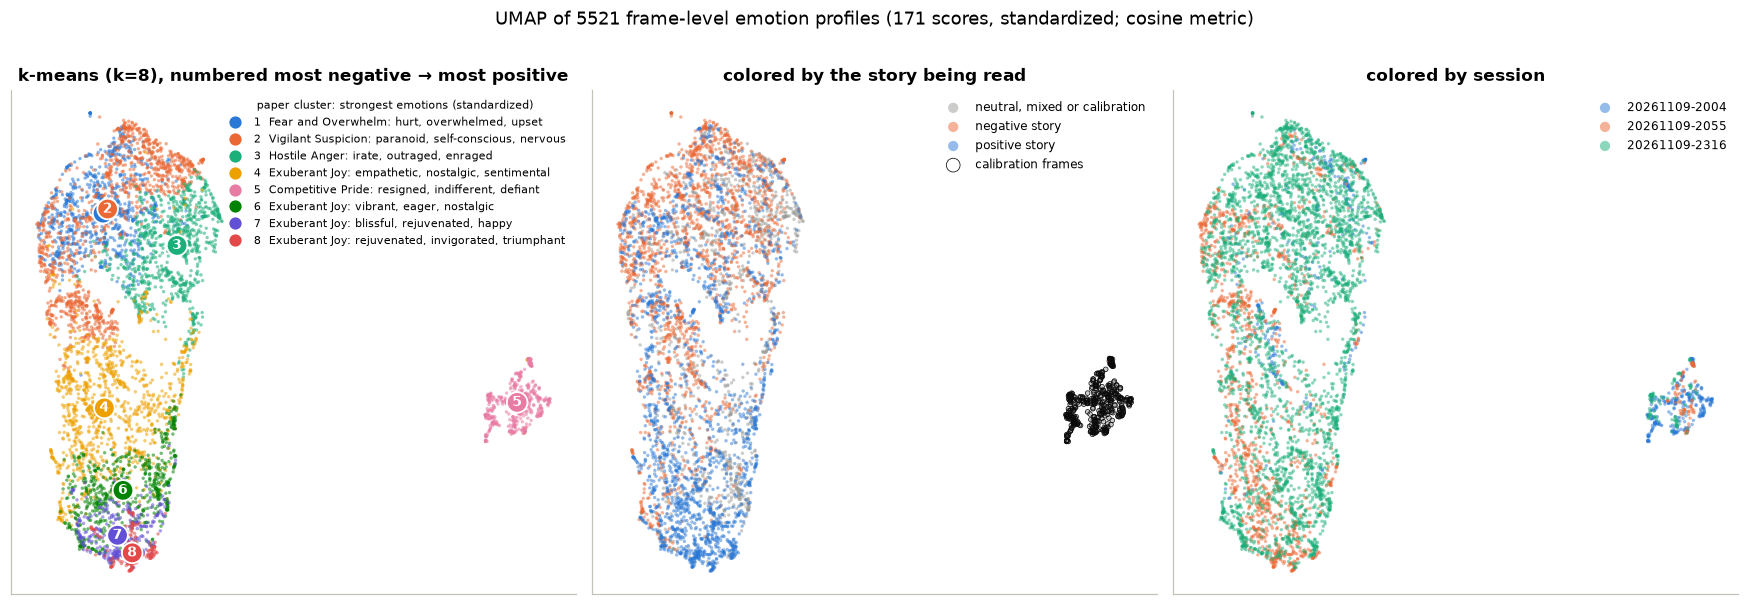

In [9]:
def crop_path(session, take, frame_index):
    p = ROOT / "data" / "video" / session / take / "frames" / f"f{frame_index:06d}.jpg"
    if not p.exists():   # a take recorded on the hosted version: fetch that one crop from the Volume
        p.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run([str(ROOT / ".venv" / "bin" / "modal"), "volume", "get", "--env", "cogmirror", "--force", "cogmirror",
                        f"/public/video/{session}/{take}/frames/{p.name}", str(p)], capture_output=True)
    return p if p.exists() else None

def thumb(session, take, frame_index, px=72):
    p = crop_path(session, take, frame_index)
    if p is None:
        return None
    im = Image.open(p).convert("RGB"); im.thumbnail((px, px))
    return np.asarray(im)

def representatives(k, n=4):
    idx = np.nonzero(lab == k)[0]
    d = np.linalg.norm(Z[idx] - km.cluster_centers_[k], axis=1)
    picks, seen = [], set()
    for i in idx[np.argsort(d)]:          # nearest to the centroid, at most one per take
        key = (rows_f[i]["session"], rows_f[i]["take"])
        if key in seen:
            continue
        seen.add(key); picks.append(i)
        if len(picks) == n:
            break
    return picks

CLUSTER_COLORS = [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"], C["green"], C["violet"], C["red"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))
# (a) clusters, with a thumbnail and the tags at each cluster's median position
ax = axes[0]
for rank, k in enumerate(order):
    m = lab == k
    ax.scatter(emb[m, 0], emb[m, 1], s=5, color=CLUSTER_COLORS[rank], alpha=0.55, edgecolor="none", label=f"{tags[k][0]}")
for rank, k in enumerate(order):
    m = lab == k
    cx, cy = np.median(emb[m, 0]), np.median(emb[m, 1])
    ax.text(cx, cy, str(number[k]), ha="center", va="center", fontsize=9, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.25", fc=CLUSTER_COLORS[rank], ec="white", lw=1.2))
handles = [plt.Line2D([], [], marker="o", ls="", color=CLUSTER_COLORS[rank], ms=7,
                      label=f"{number[k]}  {tags[k][0]}: {', '.join(tags[k][1])}") for rank, k in enumerate(order)]
ax.set_title(f"k-means (k={K}), numbered most negative → most positive")
ax.legend(handles=handles, fontsize=7, loc="upper right", title="paper cluster: strongest emotions (standardized)", title_fontsize=7)
# (b) story polarity
ax = axes[1]
pol = np.array([{1: 1, -1: -1}.get(r["pol"], 0) for r in rows_f]); calib = np.array([r["cond"] == "calibration" for r in rows_f])
for val, col, name in ((0, NEU_COL, "neutral, mixed or calibration"), (-1, NEG_COL, "negative story"), (1, POS_COL, "positive story")):
    m = (pol == val) & ~(calib & (val != 0))
    ax.scatter(emb[m, 0], emb[m, 1], s=5, color=col, alpha=0.5, edgecolor="none", label=name)
ax.scatter(emb[calib, 0], emb[calib, 1], s=9, facecolor="none", edgecolor=C["ink"], lw=0.5, label="calibration frames")
ax.set_title("colored by the story being read"); ax.legend(fontsize=8, markerscale=3)
# (c) session
ax = axes[2]
sessions = sorted({r["session"] for r in rows_f})
for i, sess in enumerate(sessions):
    m = np.array([r["session"] == sess for r in rows_f])
    ax.scatter(emb[m, 0], emb[m, 1], s=5, color=CLUSTER_COLORS[i], alpha=0.5, edgecolor="none", label=sess)
ax.set_title("colored by session"); ax.legend(fontsize=8, markerscale=3)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f"UMAP of {len(P)} frame-level emotion profiles (171 scores, standardized; cosine metric)", y=1.01)
fig.tight_layout(); save(fig, "07_profile_umap"); plt.show()

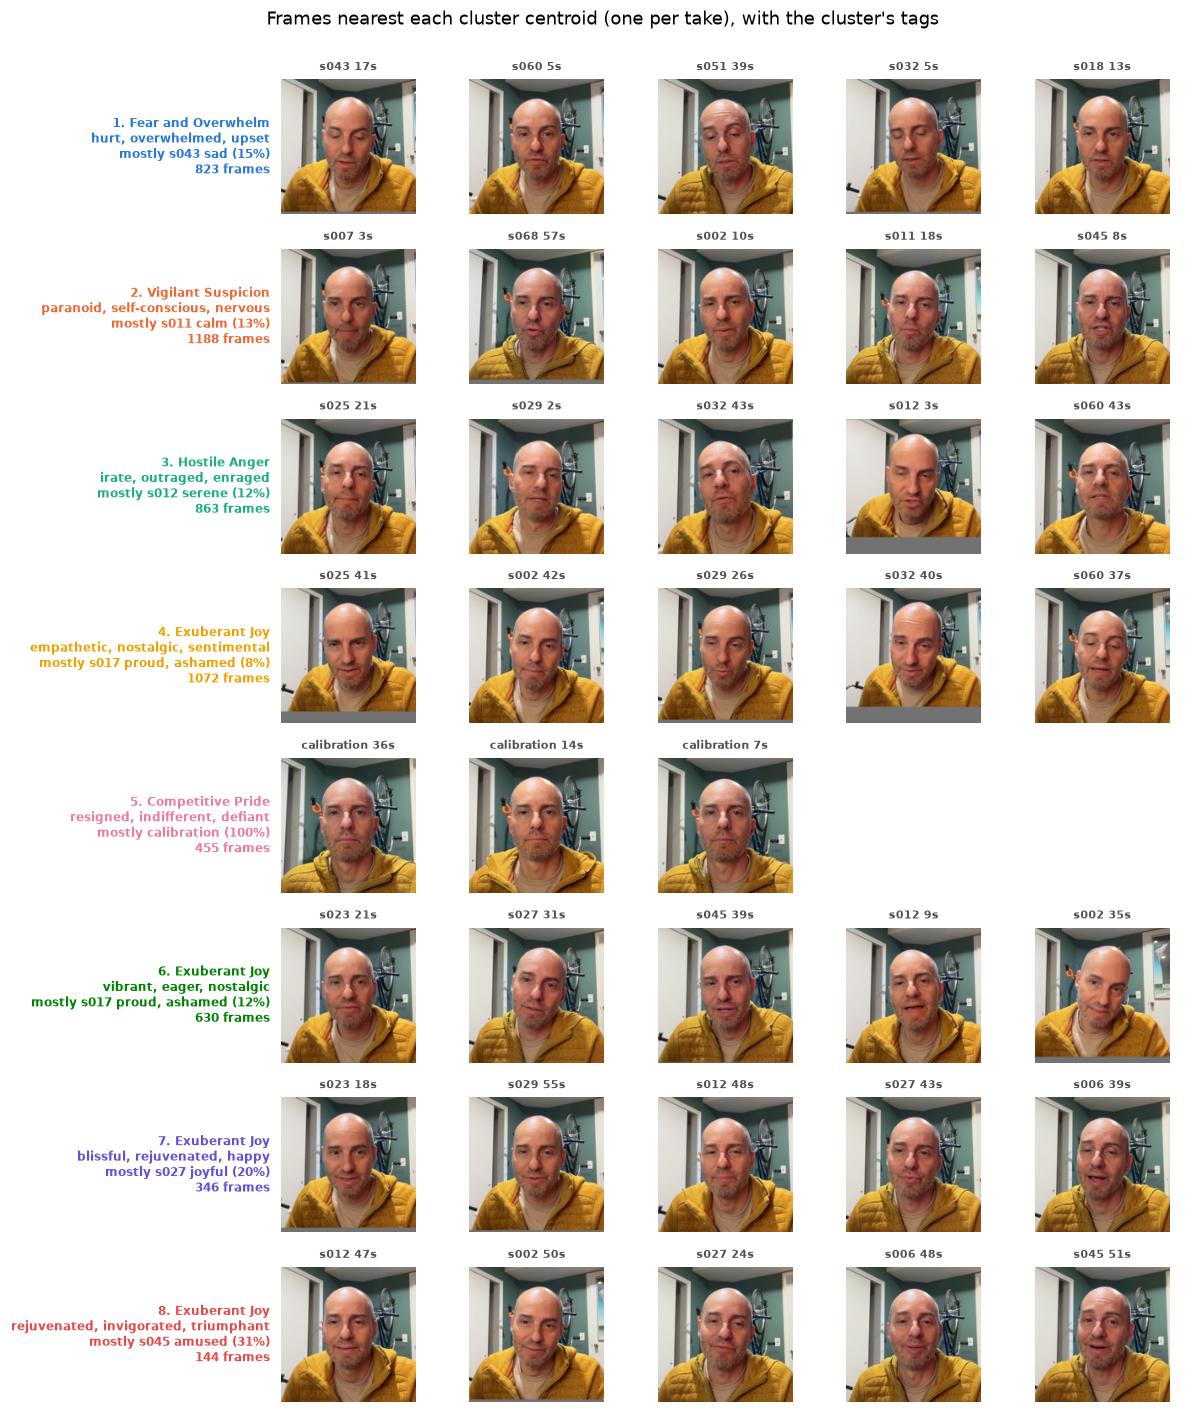

In [10]:
n_rep = 5
fig, axes = plt.subplots(K, n_rep, figsize=(1.55 * n_rep + 3.2, 1.6 * K))
for row, k in enumerate(order):
    reps = representatives(k, n_rep)
    paper_name, top, mostly = tags[k]
    for col in range(n_rep):
        ax = axes[row, col]; ax.axis("off")
        if col < len(reps):
            r = rows_f[reps[col]]
            im = thumb(r["session"], r["take"], r["frame_index"], 160)
            if im is not None:
                ax.imshow(im)
            ax.set_title(f"{r['take'].split('_')[1]} {r['t']:.0f}s", fontsize=7, color=C["ink2"])
    axes[row, 0].text(-0.08, 0.5, f"{number[k]}. {paper_name}\n{', '.join(top)}\nmostly {mostly[0]}\n{(lab == k).sum()} frames",
                      transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=8, color=CLUSTER_COLORS[row], fontweight="bold")
fig.suptitle("Frames nearest each cluster centroid (one per take), with the cluster's tags", y=1.0)
fig.tight_layout(); save(fig, "08_cluster_thumbnails"); plt.show()

### Cluster profiles over the paper's ten clusters

**What it shows.** Down the rows, the blue (positive) cells move from the right-hand, negative columns to the left-hand, positive ones: the clusters are ordered by valence, and each is strongest in a neighbouring group of the paper's clusters rather than in one alone.

How to read it: each row is one of our frame clusters; each column one of the paper's Table 12 clusters (ordered by valence). The cell is the centroid's mean standardized score over that cluster's emotions. A readout that organizes like the paper would show one strong column per row, moving from the warm to the cool side down the rows.

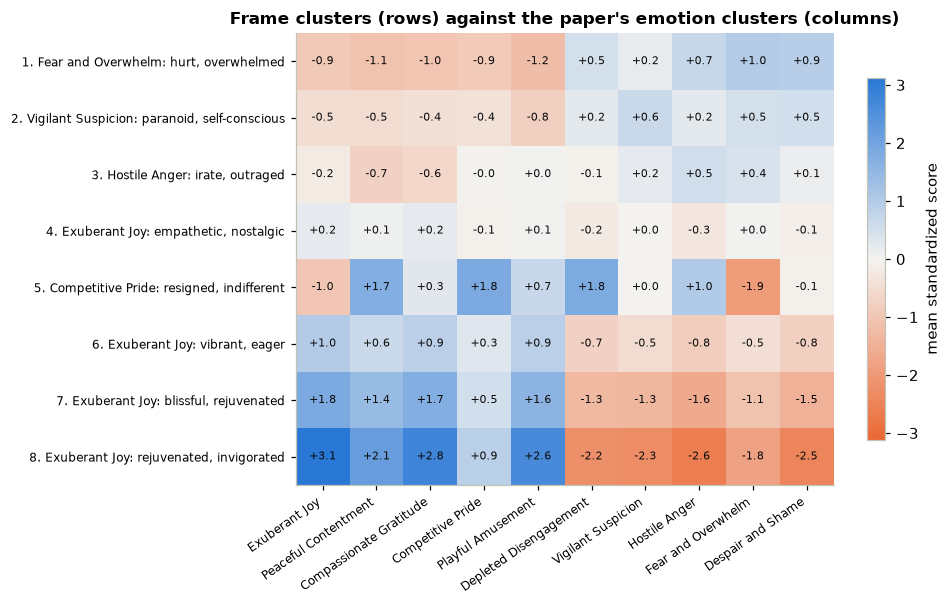

In [11]:
from matplotlib.colors import LinearSegmentedColormap
paper_clusters = list(S.CLUSTERS)
M_ = np.zeros((K, len(paper_clusters)))
for row, k in enumerate(order):
    c = Z[lab == k].mean(0)
    for j, pc in enumerate(paper_clusters):
        idx = [i for i, e in enumerate(EMOS) if S.CLUSTER_OF.get(e) == pc]
        M_[row, j] = c[idx].mean() if idx else np.nan
div = LinearSegmentedColormap.from_list("div", [NEG_COL, "#f4f3f0", POS_COL])
fig, ax = plt.subplots(figsize=(9, 0.5 * K + 1.6))
v = np.nanmax(np.abs(M_))
im = ax.imshow(M_, cmap=div, vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(len(paper_clusters))); ax.set_xticklabels(paper_clusters, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(K)); ax.set_yticklabels([f"{number[k]}. {tags[k][0]}: {', '.join(tags[k][1][:2])}" for k in order], fontsize=8)
for i in range(K):
    for j in range(len(paper_clusters)):
        ax.text(j, i, f"{M_[i, j]:+.1f}", ha="center", va="center", fontsize=7, color=C["ink"])
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="mean standardized score")
ax.set_title("Frame clusters (rows) against the paper's emotion clusters (columns)")
fig.tight_layout(); save(fig, "09_cluster_profiles"); plt.show()

## 8. The gate table, for the record

The numbers behind section 1, as the report prints them.

In [12]:
from IPython.display import Markdown
rows = ["| Variant | n | valence r (p story) | PC2–4 r | cosine (p) | top-5 (p) | turn step, n (p shift) |", "|---|---|---|---|---|---|---|"]
for vk, vlabel in variants:
    R = H.get(vk)
    if not R or "p" not in R:
        continue
    pc = ", ".join(f"{x:+.2f}" for x in R["components"]["pearson"][1:4])
    tn = R["turn"]
    rows.append(f"| {vlabel} | {R['n_segments']} | {R['valence_r']:+.2f} ({R['p']['valence_r_story']:.2f}) | {pc} | "
                f"{R['cosine']:+.2f} ({R['p']['cosine_story']:.2f}) | {R['retrieval']['top5']:.2f} ({R['p']['top5_story']:.2f}) | "
                f"{tn['mean_signed_step']:+.2f}, {tn['n_stories']} ({R['p'].get('turn_shift', float('nan')):.2f}) |")
Markdown("\n".join(rows))

| Variant | n | valence r (p story) | PC2–4 r | cosine (p) | top-5 (p) | turn step, n (p shift) |
|---|---|---|---|---|---|---|
| zero-training readout | 123 | -0.01 (0.23) | +0.02, +0.16, +0.32 | +0.05 (0.07) | 0.04 (0.65) | +0.00, 3 (0.51) |
| ridge map (face → text PCs) | 123 | +0.05 (0.31) | +0.15, +0.20, +0.25 | +0.18 (0.01) | 0.08 (0.04) | -0.18, 3 (0.91) |
| blendshape ridge (baseline) | 123 | +0.14 (0.28) | +0.09, -0.01, +0.13 | +0.14 (0.04) | 0.09 (0.02) | -0.17, 3 (0.63) |

## 9. Earlier gates (M1 and M2), for reference

**What it shows.** The text-derived emotion directions read acted faces with no training, on par with models trained for the task (Gate 1), and the readout survives speech and motion in video (Gate 2). These are the numbers behind the first two summary claims; they come from the work plan, not from this notebook's inputs.

| Gate | Check | Result |
|---|---|---|
| 0 | gemotions vectors reproduced from the released caches | exact at layer 20; deep layers numerically sensitive, with per-emotion score correlation ≥ 0.986 (median 0.996) against the released vectors |
| 1 | Valence, held-out actors, two frames per clip (zero-training) | AUC 0.982 |
| 1 | 4-way among negative emotions (angry, sad, afraid, disgusted) | 57.6% (chance 25%; human raters 66%) |
| 1 | Baselines on the same clips: HSEmotion / blendshape regression / verbal next-word | 0.979 & 58.5% / 0.943 & 57.9% / 0.978 & 46.0% |
| 1 | Noise floor: expression gap over nuisance shifts (crop, lighting; JPEG 9×, batch composition 43×) | 14–18× |
| 2 | Lexical control in acted video: variance explained by emotion vs by the sentence spoken | η² 0.729 vs 0.004 |
| 2 | Speech-motion floor: happy − negative gap over within-neutral SD, 1.5 s windows | 10 SD |
| 2 | Expression onsets within ±1 s of blendshape onsets | 79% (RAVDESS), 85% (CREMA-D) |

Details and the full tables: `docs/face-emotion-vectors-workplan.md` and `docs/results/`.